# Cheat sheet: pivot tables and charts

The examples use a made-up DataFrame `shop` with columns `city`, `month`, `product`, `amount`, so you can adapt them to your exercises.

## 1. `pivot_table`: the 4 main arguments

| Argument | Meaning | Excel word |
|---|---|---|
| `index` | What goes on the **rows** | Rows |
| `columns` | What goes on the **columns** | Columns |
| `values` | The numbers to calculate | Values |
| `aggfunc` | How to calculate them | Summarize by |

```python
shop.pivot_table(
    index="city",
    columns="product",
    values="amount",
    aggfunc="sum",
)
```

This gives one row per city, one column per product, and in each cell the sum of `amount`.

## 2. Options

| Goal | Code |
|---|---|
| Only rows and values (no columns) | `shop.pivot_table(index="city", values="amount", aggfunc="mean")` |
| Several value columns | `values=["amount", "quantity"]` |
| Several functions | `aggfunc=["mean", "sum"]` |
| A different function per column | `aggfunc={"amount": "sum", "quantity": "mean"}` |
| Replace empty cells | `fill_value=0` |
| Add totals | `margins=True` |
| Default function | If you do not write `aggfunc`, pandas uses the **mean** |

## 3. Common `aggfunc` values

| Text | Meaning |
|---|---|
| `"mean"` | Average |
| `"sum"` | Sum |
| `"max"` / `"min"` | Biggest / smallest |
| `"count"` | Number of values |
| `"median"` | Median |
| `"std"` | Standard deviation |

Read the statement carefully: "the **maximum** of ..." and "the **sum** of ..." and "the **average** of ..." each point to a different `aggfunc`.

## 4. `pd.crosstab` (the other syntax)

| Goal | Code |
|---|---|
| Count of each combination | `pd.crosstab(shop["city"], shop["product"])` |
| With a calculation | `pd.crosstab(shop["city"], shop["product"], values=shop["amount"], aggfunc="sum")` |
| Percentages by row | `pd.crosstab(shop["city"], shop["product"], normalize="index")` |
| Totals | `margins=True` |

Differences with `pivot_table`: `crosstab` is a pandas function, so you write `pd.crosstab(...)`. It takes **columns of data** (like `shop["city"]`), not just names. Without `values`, it counts. The exercise says you can choose, so `pivot_table` is usually the more direct one.

## 5. Read and shape the result

| Goal | Code |
|---|---|
| See the row labels | `table.index` |
| See the column labels | `table.columns` |
| Rows become a normal column | `table = table.reset_index()` |
| Pick a column | `table["product_name"]` |
| Sort | `table.sort_values("column_name")` |
| Rename columns | `table.rename(columns={"old": "new"})` |

Remember: in a pivot table, the `index` is **not** a normal column. After `reset_index()`, it becomes one, which is easier for some charts. This is the tip in your statement.

When you use `columns=` **and** several `values`, the column names have two levels (a MultiIndex). Without `columns=`, the column names are just the value names.

## 6. Quick charts from a pivot table

| Goal | Code |
|---|---|
| Column chart (vertical bars) | `table.plot(kind="bar")` or `table.plot.bar()` |
| Line chart | `table.plot(kind="line")` or `table.plot.line()` |
| Horizontal bars | `table.plot.barh()` |
| Stacked bars | `table.plot.bar(stacked=True)` |
| Choose the colour | `color="blue"` |
| Title | `title="My title"` |
| Axis labels | `xlabel="Month"`, `ylabel="Value"` |

A pivot table with the months on rows and one value column plots well with `.plot.bar()`: one bar per month.

## 7. Two charts in one (bars + line)

When the two measures have different scales (for example degrees and hours), use **two Y axes**.

| Step | Code |
|---|---|
| Imports | `import matplotlib.pyplot as plt` |
| Figure and first axis | `fig, ax1 = plt.subplots(figsize=(10, 5))` |
| Bars on the first axis | `ax1.bar(x_values, y_values, color="blue")` |
| Second axis, same X | `ax2 = ax1.twinx()` |
| Line on the second axis | `ax2.plot(x_values, y2_values, color="red")` |
| Labels | `ax1.set_xlabel(...)`, `ax1.set_ylabel(...)`, `ax2.set_ylabel(...)` |
| Show | `plt.show()` |

Where do `x_values` and the `y_values` come from? From the columns of your table after `reset_index()`, for example `table["month_column"]`.

Other tools:

| Library | Idea |
|---|---|
| Seaborn | `sns.barplot(data=table, x=..., y=...)` and `sns.lineplot(data=table, x=..., y=..., ax=ax2)` |
| Plotly | `px.bar(table, x=..., y=...)` for a simple bar chart |

With seaborn, use `ax=` to draw on the chosen axis, as you did in the previous exercise.

## 8. Tools by mission

| Mission | Tools to look at |
|---|---|
| 1 | `pivot_table` with `index`, `columns`, `values` and an `aggfunc` |
| 2 | Same, with another `index` and `columns`, and no `aggfunc` choice to make beyond what the statement says |
| 3 | `index` and `values` with an `aggfunc`, then `.plot.bar()` |
| 4 | `values` as a **list**, with `aggfunc` and `index` |
| Chart | `reset_index()`, matplotlib with `twinx()` |

## 9. Common mistakes

| Error | Cause | Fix |
|---|---|---|
| Table is empty or wrong | `index` and `columns` swapped | Rows are `index`, columns are `columns` |
| `KeyError` | Column name misspelled | Check with `df.columns` |
| Lots of `NaN` | Some row and column combinations have no data | Use `fill_value` if you want 0 instead |
| Values look like averages when you wanted sums | `aggfunc` forgotten (default is mean) | Always write `aggfunc` |
| `DataError: No numeric types to aggregate` | `values` is a text column | Use a numeric column |
| Chart has a strange X axis | The `index` is not a column | `reset_index()`, or use the table's index as X |
| Bars and line are hard to read together | Different scales | Use `twinx()` |
| Month labels in the wrong order | Months are text | Use the month number column, or sort it |

## 10. PEP 8 reminder

The exercise example writes `values = 'MAX_TEMPERATURE_C'` with spaces around `=`. PEP 8 asks for **no spaces** around `=` in keyword arguments: `values="MAX_TEMPERATURE_C"`. Also:

- Use one quote style in a file.
- When a call is longer than 79 characters, put one argument per line, as in the first example.
- Add a space after `#` in comments.
- Imports at the top.

# Execute the code below

In [2]:
import pandas as pd
import numpy as np
link = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather2019.csv"
df_weather = pd.read_csv(link)

In [ ]:
#columns = colonnes
#index = lignes
#values = valeurs
#aggfunc = fonction d'agrégation

shop.pivot_table(
    index="city",
    columns="product",
    values="amount",
    aggfunc="sum",
)

# You have now a DataFrame with lots of weather data

In [3]:
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WINDTEMP_MAX_C,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.0,...,3,116,143,176,0,1,5.1,very bad,1,1
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.0,...,3,119,116,116,0,1,8.7,very bad,1,2
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.0,...,-4,116,116,116,0,1,8.7,very bad,1,3
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.0,...,-4,116,116,122,0,1,5.1,very bad,1,4
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.0,...,-2,143,116,116,0,1,8.7,very bad,1,5


# PIVOT TABLE

## It's like in Excel, but with Pandas

There are 2 syntaxes, choose your preferred :
- As a method : YOUR_DATAFRAME.pivot_table()
- As a function : pd.crosstab()

In [4]:
# Example
df_weather.pivot_table(values = 'MAX_TEMPERATURE_C', index = 'MONTH', aggfunc = 'mean')

,MAX_TEMPERATURE_C
MONTH,
1,8.161290
2,12.750000
3,13.064516
4,14.900000
5,16.870968
6,22.166667
7,26.806452
8,25.290323
9,22.533333


## Create a Pivot table with :
- Months on rows
- the maximum of Max Temperature on values
- Opinion on columns

In [5]:
# Hop !
df_weather.pivot_table(columns = 'OPINION', values = 'MAX_TEMPERATURE_C', index = 'MONTH', aggfunc = 'max')

OPINION,bad,good,not good not bad,very bad,very good
MONTH,,,,,
1,11.0,NaN,NaN,10.0,NaN
2,13.0,20.0,17.0,12.0,NaN
3,14.0,19.0,17.0,12.0,NaN
4,18.0,24.0,19.0,14.0,NaN
5,19.0,25.0,20.0,15.0,NaN
6,23.0,32.0,34.0,15.0,29.0
7,31.0,33.0,39.0,22.0,33.0
8,24.0,33.0,30.0,NaN,29.0
9,21.0,31.0,20.0,20.0,NaN


## Pivot table with :
- Days on rows
- Precipitation on values
- Months on columns


In [7]:
# Hop !
df_weather.pivot_table(columns = 'MONTH', values = 'PRECIP_TOTAL_DAY_MM', index = 'DAY')

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
DAY,,,,,,,,,,,,
1,0.2,7.3,0.0,2.0,6.0,0.0,1.0,0.0,0.0,5.7,14.5,0.0
2,0.0,1.0,4.9,1.8,0.4,0.0,0.0,0.0,0.0,0.2,11.0,0.0
3,0.0,0.0,5.4,5.2,0.5,0.5,0.0,0.0,0.0,0.3,30.0,0.0
4,0.0,18.6,11.1,1.1,0.6,6.3,0.0,0.0,0.3,1.1,4.2,0.0
5,0.0,0.8,1.1,10.1,0.3,1.5,0.6,0.1,0.0,0.4,8.0,0.0
6,0.0,9.4,47.6,6.1,0.0,2.7,7.5,4.4,0.0,1.5,1.1,0.3
7,0.0,4.0,3.4,3.0,1.2,27.3,1.7,0.1,0.2,4.3,11.4,0.4
8,0.2,1.6,0.2,1.6,17.8,3.4,0.0,0.0,0.0,3.9,3.2,9.1
9,0.0,6.3,5.3,0.8,4.4,4.0,0.0,5.5,8.4,2.6,10.1,0.6


## Pivot table with :
- Months on rows
- the sum of Precipitations on values

**Then display it as a column chart.** (optionnal)

In [8]:
# Hop !
df_weather.pivot_table(values = 'PRECIP_TOTAL_DAY_MM', index = 'MONTH', aggfunc = 'sum')

,PRECIP_TOTAL_DAY_MM
MONTH,
1,58.2
2,82.5
3,103.4
4,99.7
5,71.6
6,77.2
7,40.6
8,33.2
9,60.1


## Pivot table with :
- Months on rows
- the average of Max Temperature on a first column of values
- the average of Sunhours on a second column of values

In [9]:
# Hop !

df_weather.pivot_table(values =['MAX_TEMPERATURE_C', 'SUNHOUR'], index = 'MONTH', aggfunc = 'mean')

,MAX_TEMPERATURE_C,SUNHOUR
MONTH,,
1,8.161290,5.709677
2,12.750000,8.346429
3,13.064516,9.077419
4,14.900000,9.533333
5,16.870968,11.809677
6,22.166667,14.170000
7,26.806452,14.141935
8,25.290323,11.135484
9,22.533333,9.683333


# Chart
Using your favorite library (MatPlotLib, Seaborn, Plotly or what you want), draw a chart from the previous pivot table with :
- Temperature in a blue column chart
- Sunhours in a red line plot

Tip : Once your pivot table created, you can help yourself with the `.reset_index()`  method.

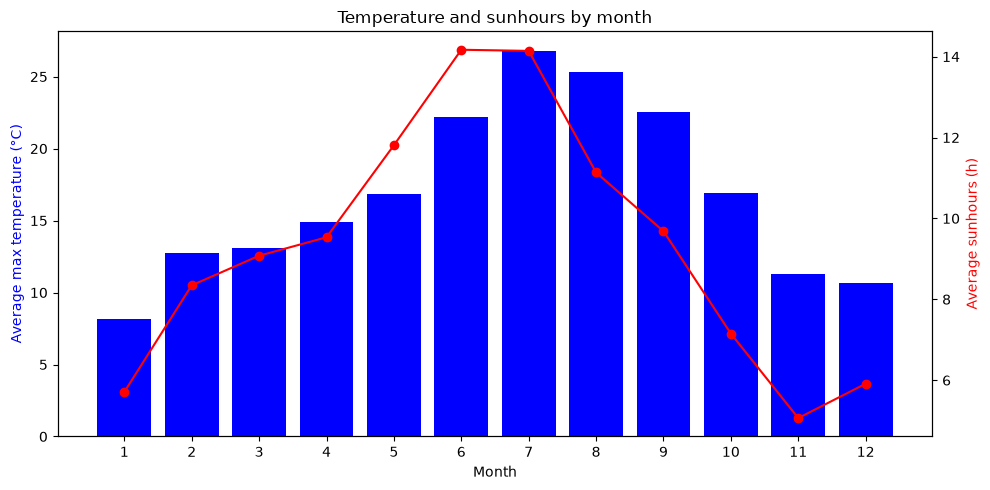

In [11]:
# Your code here
import matplotlib.pyplot as plt

# Pivot table from the previous mission, with MONTH as a normal column
pivot_month = df_weather.pivot_table(index="MONTH", values=["MAX_TEMPERATURE_C", "SUNHOUR"], aggfunc="mean").reset_index()
fig, ax_temp = plt.subplots(figsize=(10, 5))

# Temperature: blue column chart, left axis
ax_temp.bar(pivot_month["MONTH"], pivot_month["MAX_TEMPERATURE_C"], color="blue")
ax_temp.set_xlabel("Month")
ax_temp.set_ylabel("Average max temperature (°C)", color="blue")
ax_temp.set_xticks(pivot_month["MONTH"])

# Sunhours: red line plot, right axis
ax_sun = ax_temp.twinx()
ax_sun.plot(pivot_month["MONTH"], pivot_month["SUNHOUR"], color="red", marker="o")
ax_sun.set_ylabel("Average sunhours (h)", color="red")

plt.title("Temperature and sunhours by month")
plt.tight_layout()
plt.show()